# Phase 02 – Descriptive Statistics

## Objective

The purpose of this notebook is to explore the characteristics and distribution of the Competence and Employability constructs.

Descriptive statistics are performed before correlation analysis, regression modelling, and machine learning to understand the behaviour of the dataset.

The analysis includes:

- Item-level descriptive statistics
- Construct-level descriptive statistics
- Frequency distributions
- Data visualizations
- Distribution analysis using skewness and kurtosis
- Comparison between real and synthetic observations

The results provide an initial understanding of respondents' competence levels and employability levels.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

## 2. Load Prepared Phase 02 Dataset

The processed dataset created during the preprocessing stage is loaded.

This dataset contains:

- Competence items (C1–C10)
- Employability items (EVS1–EVS12)
- Composite scores
- Validated sub-dimension scores
- Data source information

In [2]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase2_competence":
    PROJECT_DIR = PROJECT_DIR.parent.parent


DATA_FILE = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "phase2_competence_prepared.csv"
)


df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully
Dataset shape: (1000, 34)


,Response_ID,C1,C2,C3,C4,C5,C6,C7,C8,C9,...,Comp_avg,EVS_avg,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg
0,1,3,3,4,4,3,3,3,3,4,...,3.3,4.750000,3.50,3.000000,3.333333,5.000000,4.0,4.75,5.0,5.0
1,2,3,4,4,3,4,4,4,4,4,...,3.7,3.500000,3.50,4.000000,3.666667,3.666667,3.5,3.75,4.0,2.5
2,3,3,4,3,3,3,4,3,4,4,...,3.4,3.750000,3.25,3.333333,3.666667,3.666667,4.0,3.75,4.0,3.5
3,4,4,4,4,4,4,4,4,4,4,...,3.9,4.000000,4.00,4.000000,3.666667,4.000000,4.0,4.00,4.0,4.0
4,5,4,4,4,4,4,5,5,4,4,...,4.3,4.333333,4.00,4.666667,4.333333,4.000000,4.5,4.50,5.0,4.0


## 3. Define Research Variables

The variables are grouped according to the research framework.

Competence represents the independent construct.

Employability represents the dependent construct.

In [3]:
competence_items = [
    "C1","C2","C3","C4","C5",
    "C6","C7","C8","C9","C10"
]


competence_constructs = [
    "Comp_avg",
    "LifeCareer_avg",
    "LearningInnovation_avg",
    "ITMedia_avg"
]


evs_items = [
    "EVS1","EVS2","EVS3","EVS4",
    "EVS5","EVS6","EVS7","EVS8",
    "EVS9","EVS10","EVS11","EVS12"
]


employability_constructs = [
    "EVS_avg",
    "HumanCapital_avg",
    "SocialCapital_avg",
    "CareerIdentity_avg",
    "EnvironmentalMonitoring_avg",
    "Balance_avg"
]

## 4. Dataset Overview

A general overview is generated to confirm the number of observations and variables used in the descriptive analysis.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 34 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Response_ID                  1000 non-null   int64  
 1   C1                           1000 non-null   int64  
 2   C2                           1000 non-null   int64  
 3   C3                           1000 non-null   int64  
 4   C4                           1000 non-null   int64  
 5   C5                           1000 non-null   int64  
 6   C6                           1000 non-null   int64  
 7   C7                           1000 non-null   int64  
 8   C8                           1000 non-null   int64  
 9   C9                           1000 non-null   int64  
 10  C10                          1000 non-null   int64  
 11  EVS1                         1000 non-null   int64  
 12  EVS2                         1000 non-null   int64  
 13  EVS3                         1

## 5. Real and Synthetic Data Distribution

The dataset contains both original and TVAE-generated observations.

The distribution of data sources is examined to understand the composition of the dataset before further analysis.

In [5]:
source_summary = (
    df["data_source"]
    .value_counts()
    .reset_index()
)

source_summary.columns = [
    "Data_Source",
    "Count"
]

source_summary

,Data_Source,Count
0,synthetic,734
1,real,266


In [6]:
source_percentage = (
    df["data_source"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

source_percentage

data_source
synthetic    73.4
real         26.6
Name: proportion, dtype: float64

## 6. Item-Level Descriptive Statistics

Descriptive statistics are calculated for each questionnaire item.

The analysis includes:

- Mean
- Standard deviation
- Minimum value
- Maximum value

This identifies the overall response tendency and variability of each item.

In [7]:
item_columns = (
    competence_items
    +
    evs_items
)


item_statistics = (
    df[item_columns]
    .describe()
    .T
)


item_statistics = item_statistics[
    [
        "mean",
        "std",
        "min",
        "max"
    ]
]


item_statistics

,mean,std,min,max
C1,3.985,0.436997,1.0,5.0
C2,3.985,0.457148,1.0,5.0
C3,3.709,0.576760,1.0,5.0
C4,3.680,0.598296,1.0,5.0
C5,3.947,0.392868,1.0,5.0
C6,4.003,0.434948,1.0,5.0
C7,3.965,0.440419,1.0,5.0
C8,3.877,0.487964,1.0,5.0
C9,3.992,0.431419,1.0,5.0
C10,3.875,0.497617,1.0,5.0


## 7. Construct-Level Descriptive Statistics

Construct-level analysis is performed using theoretically defined questionnaire dimensions.

This provides a higher-level understanding of Competence and Employability.

In [8]:
construct_columns = (
    competence_constructs
    +
    employability_constructs
)


construct_statistics = (
    df[construct_columns]
    .describe()
    .T
)


construct_statistics = construct_statistics[
    [
        "mean",
        "std",
        "min",
        "max"
    ]
]


construct_statistics

,mean,std,min,max
Comp_avg,3.901800,0.339959,1.0,5.0
LifeCareer_avg,3.839750,0.403013,1.0,5.0
LearningInnovation_avg,3.971667,0.351329,1.0,5.0
ITMedia_avg,3.914667,0.384099,1.0,5.0
EVS_avg,4.101333,0.351081,1.0,5.0
HumanCapital_avg,3.935333,0.356450,1.0,5.0
SocialCapital_avg,3.889500,0.417389,1.0,5.0
CareerIdentity_avg,4.426000,0.545042,1.0,5.0
EnvironmentalMonitoring_avg,3.972000,0.421181,1.0,5.0
Balance_avg,3.977500,0.394841,1.0,5.0


## 8. Likert Response Frequency Distribution

Frequency distributions are generated to understand how respondents answered each questionnaire item.

This helps identify whether responses are concentrated toward agreement or disagreement.

In [9]:
c1_frequency = (
    df["C1"]
    .value_counts()
    .sort_index()
)

c1_frequency

C1
1      4
2     12
3     43
4    877
5     64
Name: count, dtype: int64

In [10]:
frequency_tables = {}

for col in item_columns:
    frequency_tables[col] = (
        df[col]
        .value_counts()
        .sort_index()
    )

frequency_tables["C1"]

C1
1      4
2     12
3     43
4    877
5     64
Name: count, dtype: int64

## 9. Distribution Visualization

Histograms are created to examine the distribution of the main research constructs.

The distributions of Competence and Employability scores are visualized.

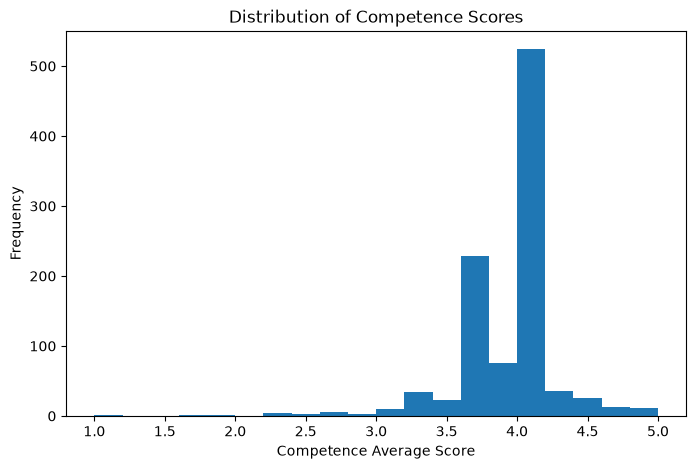

In [11]:
plt.figure(figsize=(8,5))

plt.hist(
    df["Comp_avg"],
    bins=20
)

plt.xlabel(
    "Competence Average Score"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Distribution of Competence Scores"
)

plt.show()

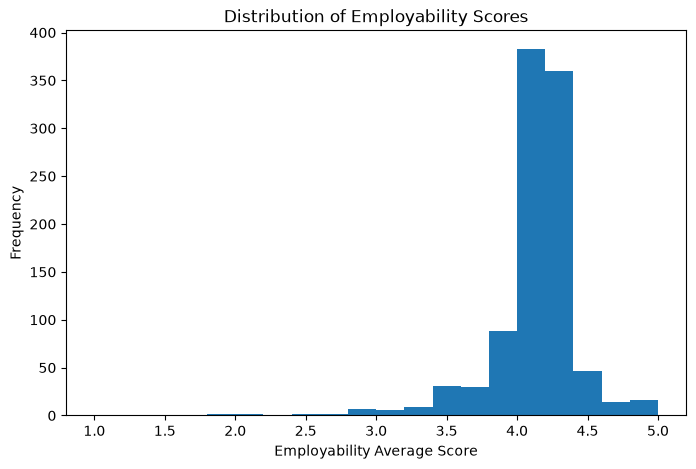

In [12]:
plt.figure(figsize=(8,5))

plt.hist(
    df["EVS_avg"],
    bins=20
)

plt.xlabel(
    "Employability Average Score"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Distribution of Employability Scores"
)

plt.show()

## 10. Box Plot Analysis

Box plots are used to identify:

- Median values
- Score dispersion
- Possible outliers

This provides additional understanding of score variability.

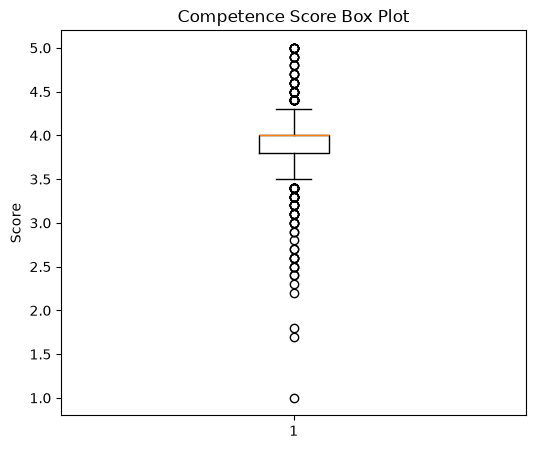

In [13]:
plt.figure(figsize=(6,5))

plt.boxplot(
    df["Comp_avg"]
)

plt.title(
    "Competence Score Box Plot"
)

plt.ylabel(
    "Score"
)

plt.show()

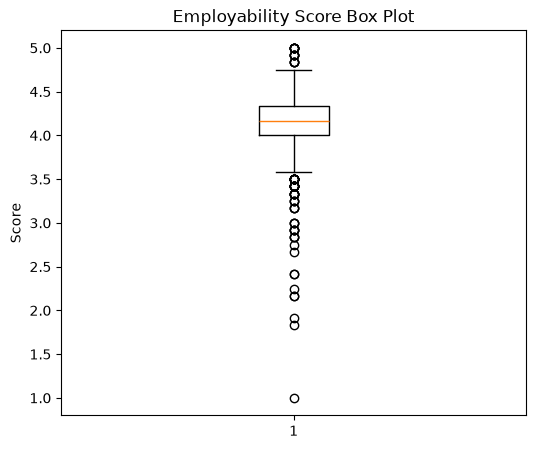

In [14]:
plt.figure(figsize=(6,5))

plt.boxplot(
    df["EVS_avg"]
)

plt.title(
    "Employability Score Box Plot"
)

plt.ylabel(
    "Score"
)

plt.show()

Skewness and Kurtosis

## 11. Distribution Shape Analysis

Skewness and kurtosis are calculated to understand the distribution characteristics of the main constructs.

These values help evaluate whether the variables show approximately symmetric distributions before statistical modelling.

In [15]:
distribution_analysis = pd.DataFrame({
    "Skewness": df[construct_columns].skew(),
    "Kurtosis": df[construct_columns].kurtosis()
})


distribution_analysis

,Skewness,Kurtosis
Comp_avg,-1.859320,12.312598
LifeCareer_avg,-1.486645,7.842657
LearningInnovation_avg,-2.358675,15.489206
ITMedia_avg,-1.589392,9.145634
EVS_avg,-2.399823,13.430326
HumanCapital_avg,-1.763405,11.885575
SocialCapital_avg,-2.132246,10.124890
CareerIdentity_avg,-1.490915,5.441961
EnvironmentalMonitoring_avg,-1.947785,12.892925
Balance_avg,-2.388762,15.445289


## 12. Real vs Synthetic Data Comparison

Because the dataset includes TVAE-generated observations, descriptive statistics are compared between real and synthetic groups.

This checks whether synthetic observations maintain similar statistical characteristics to the original dataset.

In [16]:
real_synthetic_summary = (
    df.groupby("data_source")
    [
        [
            "Comp_avg",
            "EVS_avg"
        ]
    ]
    .mean()
)

real_synthetic_summary

,Comp_avg,EVS_avg
data_source,,
real,3.830451,3.970238
synthetic,3.927657,4.148842


In [17]:
df.groupby("data_source")[
    [
        "Comp_avg",
        "EVS_avg"
    ]
].std()

,Comp_avg,EVS_avg
data_source,,
real,0.587683,0.587988
synthetic,0.173593,0.185739


In [19]:
REPORT_DIR = (
    PROJECT_DIR
    /
    "reports"
    /
    "phase2"
    /
    "descriptive_statistics"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [20]:
item_statistics.to_csv(
    REPORT_DIR /
    "Item_Descriptive_Statistics.csv"
)


construct_statistics.to_csv(
    REPORT_DIR /
    "Construct_Descriptive_Statistics.csv"
)


distribution_analysis.to_csv(
    REPORT_DIR /
    "Distribution_Analysis.csv"
)


real_synthetic_summary.to_csv(
    REPORT_DIR /
    "Real_Synthetic_Comparison.csv"
)

# Descriptive Statistics Summary

Descriptive analysis was conducted to understand the characteristics of the Competence and Employability constructs.

The analysis included item-level statistics, construct-level statistics, response distributions, visualization, distribution analysis, and real versus synthetic data comparison.

The findings provide an initial understanding of the dataset before performing correlation analysis, regression modelling, and machine-learning experiments.

In [21]:
distribution_analysis

,Skewness,Kurtosis
Comp_avg,-1.859320,12.312598
LifeCareer_avg,-1.486645,7.842657
LearningInnovation_avg,-2.358675,15.489206
ITMedia_avg,-1.589392,9.145634
EVS_avg,-2.399823,13.430326
HumanCapital_avg,-1.763405,11.885575
SocialCapital_avg,-2.132246,10.124890
CareerIdentity_avg,-1.490915,5.441961
EnvironmentalMonitoring_avg,-1.947785,12.892925
Balance_avg,-2.388762,15.445289


Demographic Analysis

In [22]:
df.columns.tolist()

['Response_ID',
 'C1',
 'C2',
 'C3',
 'C4',
 'C5',
 'C6',
 'C7',
 'C8',
 'C9',
 'C10',
 'EVS1',
 'EVS2',
 'EVS3',
 'EVS4',
 'EVS5',
 'EVS6',
 'EVS7',
 'EVS8',
 'EVS9',
 'EVS10',
 'EVS11',
 'EVS12',
 'data_source',
 'Comp_avg',
 'EVS_avg',
 'LifeCareer_avg',
 'LearningInnovation_avg',
 'ITMedia_avg',
 'HumanCapital_avg',
 'SocialCapital_avg',
 'CareerIdentity_avg',
 'EnvironmentalMonitoring_avg',
 'Balance_avg']

## Respondent Demographic Characteristics

The demographic characteristics of respondents were analysed to describe the study sample.

The demographic variables include:

- Gender
- Age
- Degree Program
- Internship Status

These variables are used only for describing the respondent profile and are not included as predictive features in the Competence-based Employability model.

Load original dataset for demographics

In [24]:
demographic_df = pd.read_excel(
    PROJECT_DIR
    / "data"
    / "raw"
    / "Phase2_Google_Form_Responses_From_TVAE_1000 (1).xlsx",
    sheet_name="Google_Form_Responses"
)

print(
    "Demographic dataset shape:",
    demographic_df.shape
)

demographic_df.head()

Demographic dataset shape: (1000, 29)


,Response_ID,Gender,Age,Degree Program,Internship Status,C1,C2,C3,C4,C5,...,EVS5,EVS6,EVS7,EVS8,EVS9,EVS10,EVS11,EVS12,Source_Type,Demographic_Note
0,1,Female,18–20,Information Technology,Yes,3,3,4,4,3,...,4,4,5,5,5,5,5,5,real,Synthetic demographics generated for form comp...
1,2,Female,21–23,Business Management,Yes,3,4,4,3,4,...,3,5,4,4,2,4,3,2,real,Synthetic demographics generated for form comp...
2,3,Male,18–20,Information Technology,Yes,3,4,3,3,3,...,4,5,4,3,3,4,3,4,real,Synthetic demographics generated for form comp...
3,4,Male,18–20,Engineering,Yes,4,4,4,4,4,...,4,4,4,4,4,4,4,4,real,Synthetic demographics generated for form comp...
4,5,Male,21–23,Business Management,Yes,4,4,4,4,4,...,5,5,4,4,5,5,4,4,real,Synthetic demographics generated for form comp...


In [25]:
gender_summary = (
    demographic_df["Gender"]
    .value_counts()
    .reset_index()
)

gender_summary.columns = [
    "Gender",
    "Count"
]

gender_summary

,Gender,Count
0,Female,503
1,Male,466
2,Prefer not to say,31


In [26]:
gender_percentage = (
    demographic_df["Gender"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

gender_percentage

Gender
Female               50.3
Male                 46.6
Prefer not to say     3.1
Name: proportion, dtype: float64

In [ ]:
age_summary = (
    demographic_df["Age"]
    .value_counts()
    .sort_index()
)

age_summary

In [27]:
demographic_df["Age"].describe()

count      1000
unique        4
top       21–23
freq        608
Name: Age, dtype: object

In [28]:
degree_summary = (
    demographic_df["Degree Program"]
    .value_counts()
    .reset_index()
)

degree_summary.columns = [
    "Degree Program",
    "Count"
]

degree_summary

,Degree Program,Count
0,Information Technology,477
1,Engineering,254
2,Business Management,195
3,Other,74


In [29]:
internship_summary = (
    demographic_df["Internship Status"]
    .value_counts()
    .reset_index()
)

internship_summary.columns = [
    "Internship Status",
    "Count"
]

internship_summary

,Internship Status,Count
0,Yes,813
1,No,187


In [30]:
REPORT_DIR = (
    PROJECT_DIR
    /
    "reports"
    /
    "phase2"
    /
    "descriptive_statistics"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [32]:
gender_summary.to_csv(
    REPORT_DIR / "Gender_Distribution.csv",
    index=False
)

degree_summary.to_csv(
    REPORT_DIR / "Degree_Program_Distribution.csv",
    index=False
)

internship_summary.to_csv(
    REPORT_DIR / "Internship_Status_Distribution.csv",
    index=False
)

age_summary.to_csv(
    REPORT_DIR / "Age_Distribution.csv"
)

NameError: name 'age_summary' is not defined

In [33]:
demographic_df.columns.tolist()

['Response_ID',
 'Gender',
 'Age',
 'Degree Program',
 'Internship Status',
 'C1',
 'C2',
 'C3',
 'C4',
 'C5',
 'C6',
 'C7',
 'C8',
 'C9',
 'C10',
 'EVS1',
 'EVS2',
 'EVS3',
 'EVS4',
 'EVS5',
 'EVS6',
 'EVS7',
 'EVS8',
 'EVS9',
 'EVS10',
 'EVS11',
 'EVS12',
 'Source_Type',
 'Demographic_Note']

## Demographic Profile Analysis

The demographic characteristics of respondents were analysed to describe the composition of the study sample.

The analysis includes:

- Gender distribution
- Age distribution
- Degree program distribution
- Internship status distribution

These demographic variables are used only for describing respondents and are not included as predictive variables in the Competence-based Employability model.

In [43]:
gender_summary = (
    demographic_df["Gender"]
    .value_counts()
    .reset_index()
)

gender_summary.columns = [
    "Gender",
    "Count"
]

gender_summary

,Gender,Count
0,Female,503
1,Male,466
2,Prefer not to say,31


In [44]:
gender_percentage = (
    demographic_df["Gender"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .reset_index()
)

gender_percentage.columns = [
    "Gender",
    "Percentage"
]

gender_percentage

,Gender,Percentage
0,Female,50.3
1,Male,46.6
2,Prefer not to say,3.1


In [45]:
age_summary = (
    demographic_df["Age"]
    .value_counts()
    .sort_index()
    .reset_index()
)

age_summary.columns = [
    "Age",
    "Count"
]

age_summary

,Age,Count
0,18–20,215
1,21–23,608
2,24–26,137
3,27 or above,40


In [46]:
age_percentage = (
    demographic_df["Age"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .sort_index()
    .reset_index()
)

age_percentage.columns = [
    "Age",
    "Percentage"
]

age_percentage

,Age,Percentage
0,18–20,21.5
1,21–23,60.8
2,24–26,13.7
3,27 or above,4.0


In [47]:
degree_summary = (
    demographic_df["Degree Program"]
    .value_counts()
    .reset_index()
)

degree_summary.columns = [
    "Degree Program",
    "Count"
]

degree_summary

,Degree Program,Count
0,Information Technology,477
1,Engineering,254
2,Business Management,195
3,Other,74


In [48]:
degree_percentage = (
    demographic_df["Degree Program"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .reset_index()
)

degree_percentage.columns = [
    "Degree Program",
    "Percentage"
]

degree_percentage

,Degree Program,Percentage
0,Information Technology,47.7
1,Engineering,25.4
2,Business Management,19.5
3,Other,7.4


In [49]:
internship_summary = (
    demographic_df["Internship Status"]
    .value_counts()
    .reset_index()
)

internship_summary.columns = [
    "Internship Status",
    "Count"
]

internship_summary

,Internship Status,Count
0,Yes,813
1,No,187


In [50]:
internship_percentage = (
    demographic_df["Internship Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .reset_index()
)

internship_percentage.columns = [
    "Internship Status",
    "Percentage"
]

internship_percentage

,Internship Status,Percentage
0,Yes,81.3
1,No,18.7


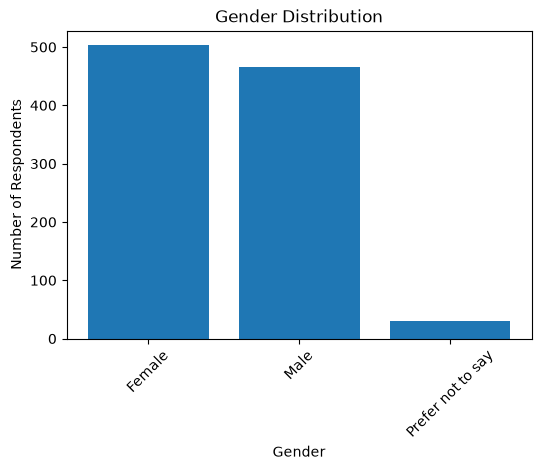

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.bar(
    gender_summary["Gender"],
    gender_summary["Count"]
)

plt.xlabel("Gender")
plt.ylabel("Number of Respondents")
plt.title("Gender Distribution")

plt.xticks(rotation=45)

plt.show()

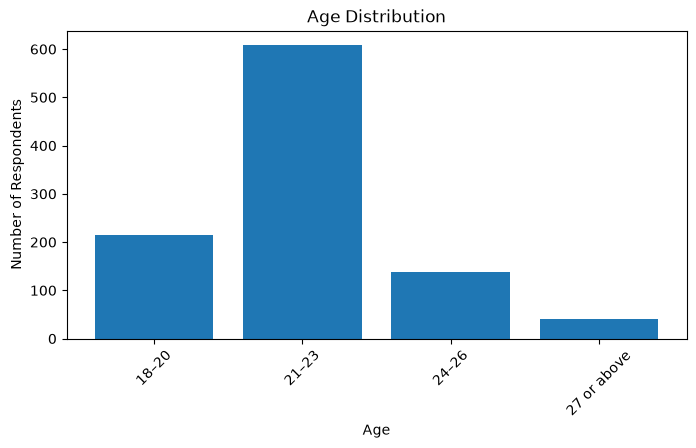

In [52]:
plt.figure(figsize=(8,4))

plt.bar(
    age_summary["Age"].astype(str),
    age_summary["Count"]
)

plt.xlabel("Age")
plt.ylabel("Number of Respondents")
plt.title("Age Distribution")

plt.xticks(rotation=45)

plt.show()

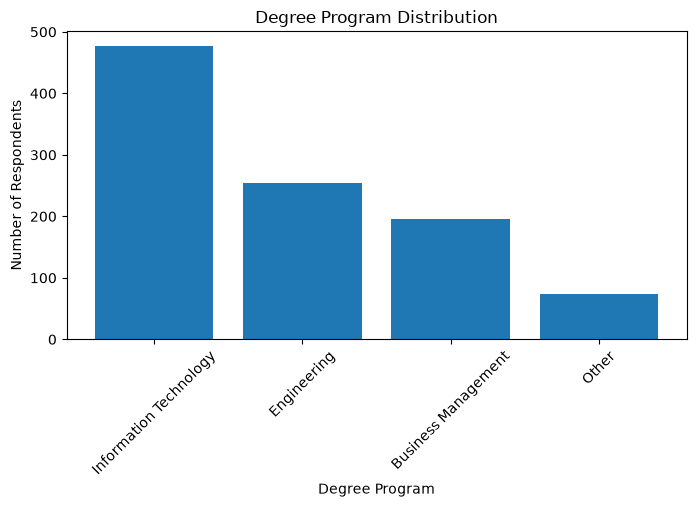

In [53]:
plt.figure(figsize=(8,4))

plt.bar(
    degree_summary["Degree Program"],
    degree_summary["Count"]
)

plt.xlabel("Degree Program")
plt.ylabel("Number of Respondents")
plt.title("Degree Program Distribution")

plt.xticks(rotation=45)

plt.show()

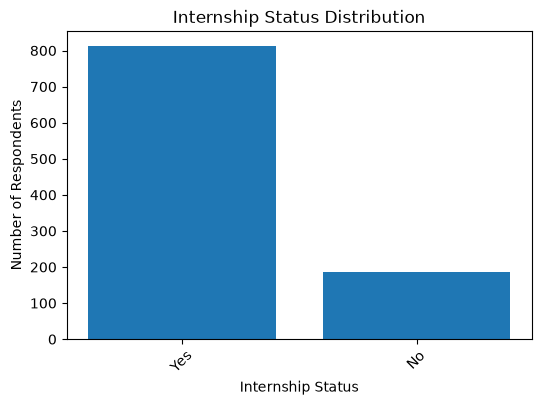

In [54]:
plt.figure(figsize=(6,4))

plt.bar(
    internship_summary["Internship Status"],
    internship_summary["Count"]
)

plt.xlabel("Internship Status")
plt.ylabel("Number of Respondents")
plt.title("Internship Status Distribution")

plt.xticks(rotation=45)

plt.show()

In [55]:
demographic_df["Internship Status"].value_counts(dropna=False)

Internship Status
Yes    813
No     187
Name: count, dtype: int64

In [56]:
for col in [
    "Gender",
    "Age",
    "Degree Program",
    "Internship Status"
]:
    print("\n", col)
    print(demographic_df[col].value_counts(dropna=False))


 Gender
Gender
Female               503
Male                 466
Prefer not to say     31
Name: count, dtype: int64

 Age
Age
21–23          608
18–20          215
24–26          137
27 or above     40
Name: count, dtype: int64

 Degree Program
Degree Program
Information Technology    477
Engineering               254
Business Management       195
Other                      74
Name: count, dtype: int64

 Internship Status
Internship Status
Yes    813
No     187
Name: count, dtype: int64


In [57]:
internship_percentage = (
    demographic_df["Internship Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .reset_index()
)

internship_percentage.columns = [
    "Internship Status",
    "Percentage"
]

internship_percentage

,Internship Status,Percentage
0,Yes,81.3
1,No,18.7


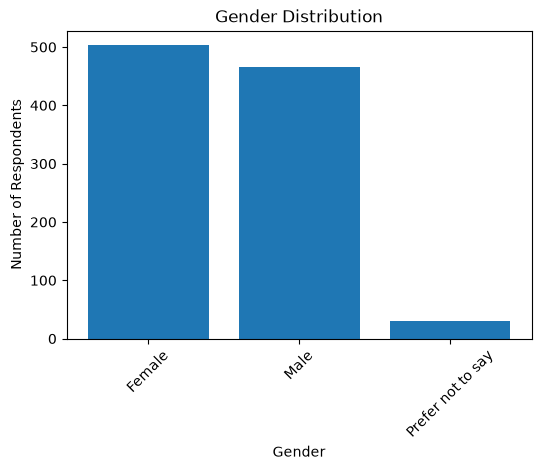

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.bar(
    gender_summary["Gender"],
    gender_summary["Count"]
)

plt.xlabel("Gender")
plt.ylabel("Number of Respondents")
plt.title("Gender Distribution")

plt.xticks(rotation=45)

plt.show()

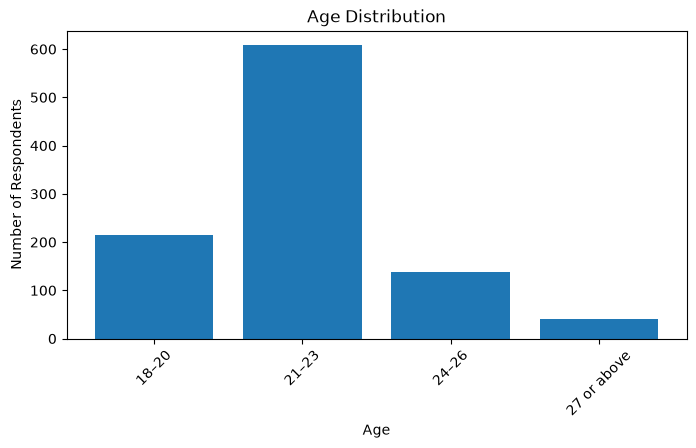

In [59]:
plt.figure(figsize=(8,4))

plt.bar(
    age_summary["Age"].astype(str),
    age_summary["Count"]
)

plt.xlabel("Age")
plt.ylabel("Number of Respondents")
plt.title("Age Distribution")

plt.xticks(rotation=45)

plt.show()

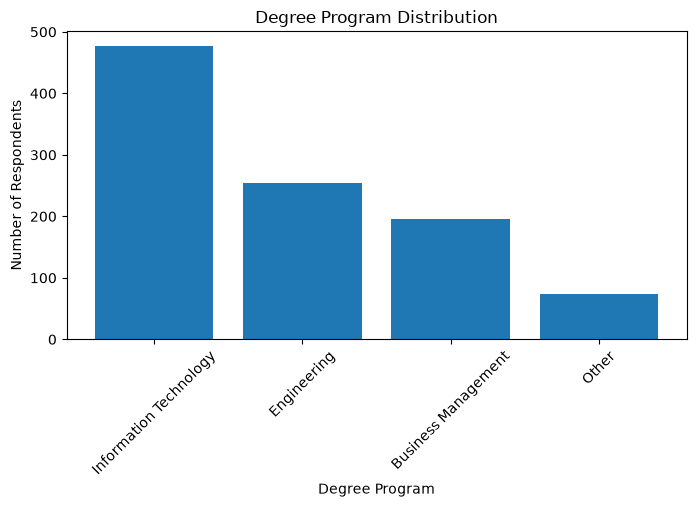

In [60]:
plt.figure(figsize=(8,4))

plt.bar(
    degree_summary["Degree Program"],
    degree_summary["Count"]
)

plt.xlabel("Degree Program")
plt.ylabel("Number of Respondents")
plt.title("Degree Program Distribution")

plt.xticks(rotation=45)

plt.show()

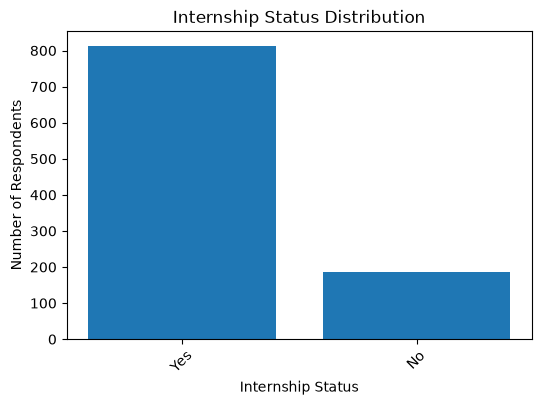

In [61]:
plt.figure(figsize=(6,4))

plt.bar(
    internship_summary["Internship Status"],
    internship_summary["Count"]
)

plt.xlabel("Internship Status")
plt.ylabel("Number of Respondents")
plt.title("Internship Status Distribution")

plt.xticks(rotation=45)

plt.show()

In [62]:
REPORT_DIR = (
    PROJECT_DIR
    /
    "reports"
    /
    "phase2"
    /
    "descriptive_statistics"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [63]:
gender_percentage.to_csv(
    REPORT_DIR / "Gender_Percentage.csv",
    index=False
)

age_percentage.to_csv(
    REPORT_DIR / "Age_Percentage.csv",
    index=False
)

degree_percentage.to_csv(
    REPORT_DIR / "Degree_Program_Percentage.csv",
    index=False
)

internship_percentage.to_csv(
    REPORT_DIR / "Internship_Status_Percentage.csv",
    index=False
)

In [64]:
construct_statistics

,mean,std,min,max
Comp_avg,3.901800,0.339959,1.0,5.0
LifeCareer_avg,3.839750,0.403013,1.0,5.0
LearningInnovation_avg,3.971667,0.351329,1.0,5.0
ITMedia_avg,3.914667,0.384099,1.0,5.0
EVS_avg,4.101333,0.351081,1.0,5.0
HumanCapital_avg,3.935333,0.356450,1.0,5.0
SocialCapital_avg,3.889500,0.417389,1.0,5.0
CareerIdentity_avg,4.426000,0.545042,1.0,5.0
EnvironmentalMonitoring_avg,3.972000,0.421181,1.0,5.0
Balance_avg,3.977500,0.394841,1.0,5.0


In [ ]:
Comp_avg
LifeCareer_avg
LearningInnovation_avg
ITMedia_avg

EVS_avg
HumanCapital_avg
SocialCapital_avg
CareerIdentity_avg
EnvironmentalMonitoring_avg
Balance_avg

In [65]:
distribution_analysis

,Skewness,Kurtosis
Comp_avg,-1.859320,12.312598
LifeCareer_avg,-1.486645,7.842657
LearningInnovation_avg,-2.358675,15.489206
ITMedia_avg,-1.589392,9.145634
EVS_avg,-2.399823,13.430326
HumanCapital_avg,-1.763405,11.885575
SocialCapital_avg,-2.132246,10.124890
CareerIdentity_avg,-1.490915,5.441961
EnvironmentalMonitoring_avg,-1.947785,12.892925
Balance_avg,-2.388762,15.445289


In [66]:
real_synthetic_summary

,Comp_avg,EVS_avg
data_source,,
real,3.830451,3.970238
synthetic,3.927657,4.148842


In [67]:
df.groupby("data_source")[
    [
        "Comp_avg",
        "EVS_avg"
    ]
].std()

,Comp_avg,EVS_avg
data_source,,
real,0.587683,0.587988
synthetic,0.173593,0.185739


In [68]:
gender_summary
age_summary
degree_summary
internship_summary

,Internship Status,Count
0,Yes,813
1,No,187


In [69]:
item_statistics

,mean,std,min,max
C1,3.985,0.436997,1.0,5.0
C2,3.985,0.457148,1.0,5.0
C3,3.709,0.576760,1.0,5.0
C4,3.680,0.598296,1.0,5.0
C5,3.947,0.392868,1.0,5.0
C6,4.003,0.434948,1.0,5.0
C7,3.965,0.440419,1.0,5.0
C8,3.877,0.487964,1.0,5.0
C9,3.992,0.431419,1.0,5.0
C10,3.875,0.497617,1.0,5.0


In [70]:
import os

for file in os.listdir(REPORT_DIR):
    print(file)

Age_Distribution.csv
Age_Percentage.csv
Construct_Descriptive_Statistics.csv
Degree_Program_Distribution.csv
Degree_Program_Percentage.csv
Distribution_Analysis.csv
Gender_Distribution.csv
Gender_Percentage.csv
Internship_Status_Distribution.csv
Internship_Status_Percentage.csv
Item_Descriptive_Statistics.csv
Real_Synthetic_Comparison.csv
